# VC · Práctica 5 — Detección de emociones faciales (FER-2013)

Comparativa de **modelos clásicos** (PCA / HOG / LBP + KNN / SVM / Stacked), una **CNN propia** (TensorFlow/Keras) y **DeepFace** sobre el dataset
[`ananthu017/emotion-detection-fer`](https://www.kaggle.com/datasets/ananthu017/emotion-detection-fer) (48×48, escala de grises, 7 clases).

**Índice**
1. Configuración y librerías
2. Carga, exploración y adecuación del dataset (class_weight, validación estratificada)
3. Utilidades de evaluación
4. Modelos clásicos (PCA, HOG, LBP + KNN / SVM / Stacked)
5. CNN en Keras
6. DeepFace
7. Comparativa final

## 1. Configuración y librerías

In [1]:
# (Opcional) instalación en el entorno Conda VC_P5. No se usa dlib.
# !pip install opencv-python mediapipe scikit-learn scikit-image tensorflow tf-keras deepface matplotlib joblib pandas tqdm

In [2]:
import os, time, json, random, warnings
from pathlib import Path
import ctypes, glob, os, site

_nv = os.path.join(site.getsitepackages()[0], "nvidia")
for _name in ["cusolver/lib/libcusolver.so.11", "curand/lib/libcurand.so.10"]:
    for _p in glob.glob(os.path.join(_nv, _name)):
        ctypes.CDLL(_p, mode=ctypes.RTLD_GLOBAL)

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
# DeepFace descarga sus pesos aquí (cámbialo si tu disco va justo de espacio)
os.environ.setdefault("DEEPFACE_HOME", os.path.abspath("./.deepface_cache"))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl_cache")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed
from tqdm.auto import tqdm

from skimage.feature import hog, local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)

# =====================  PARÁMETROS (lo único que hay que tocar)  =====================
DATA_DIR = Path(
    r"/home/cris/Proyectos/computer-vision/image-dataset/prac5_dataset"
)  # <-- CAMBIAR: carpeta que contiene train/ y test/
TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"

OUT_DIR    = Path("outputs_p5")
MODELS_DIR = OUT_DIR / "models/v1"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

SEED     = 42
IMG_SIZE = 48
VAL_SIZE = 0.20            # validación estratificada sacada de train
N_JOBS   = -1              # paralelismo para extraer características (la inferencia se mide con 1 hilo)

# Modelos clásicos
KNN_K_GRID    = [5, 11, 21]
SVM_KIND      = "rbf"      # "rbf" (SVC con subconjunto) | "linear" (LinearSVC con todo train)
SVM_MAX_TRAIN = 10_000     # nº máx. de muestras de train para SVC-RBF (coste ~ O(n^2..n^3))
SVM_C_GRID    = [1, 10]
RUN_STACKED   = True
STACK_MAX_TRAIN = 5_000

# CNN
CNN_EPOCHS, CNN_BATCH = 80, 64

# DeepFace: nº de imágenes de test (muestra estratificada, la MISMA para todos los modelos). None = todo test
DEEPFACE_N        = 1000
DEEPFACE_DETECTOR = "skip"   # las imágenes ya son caras recortadas -> sin detector (un detector falla con 48x48)

random.seed(SEED); np.random.seed(SEED)
assert TRAIN_DIR.is_dir() and TEST_DIR.is_dir(), f"No encuentro train/ y test/ en {DATA_DIR}"
print("Dataset en:", DATA_DIR.resolve())

Dataset en: /home/cris/Proyectos/computer-vision/image-dataset/prac5_dataset


## 2. Carga, exploración y adecuación del dataset
Las imágenes se leen con `np.fromfile` + `cv2.imdecode` para evitar problemas de OpenCV con rutas con tildes/espacios en Windows.

In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def read_gray(path: Path) -> np.ndarray:
    data = np.fromfile(str(path), dtype=np.uint8)
    img = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if img is not None and img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return img

def load_split(split_dir: Path, class_names=None):
    """Devuelve X (N,48,48) uint8, y (N,) int y los nombres de clase (orden alfabético = índice)."""
    if class_names is None:
        class_names = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
    X, y = [], []
    for idx, cname in enumerate(class_names):
        files = sorted(f for f in (split_dir / cname).iterdir() if f.suffix.lower() in IMG_EXT)
        for f in tqdm(files, desc=f"{split_dir.name}/{cname}", leave=False):
            img = read_gray(f)
            if img is not None:
                X.append(img); y.append(idx)
    return np.stack(X).astype(np.uint8), np.array(y, dtype=np.int64), class_names

X_full, y_full, CLASS_NAMES = load_split(TRAIN_DIR)
X_test, y_test, _ = load_split(TEST_DIR, CLASS_NAMES)
N_CLASSES = len(CLASS_NAMES)
print("Clases:", CLASS_NAMES)
print("train completo:", X_full.shape, "| test:", X_test.shape)

train/angry:   0%|          | 0/3995 [00:00<?, ?it/s]

train/disgusted:   0%|          | 0/436 [00:00<?, ?it/s]

train/fearful:   0%|          | 0/4097 [00:00<?, ?it/s]

train/happy:   0%|          | 0/7215 [00:00<?, ?it/s]

train/neutral:   0%|          | 0/4965 [00:00<?, ?it/s]

train/sad:   0%|          | 0/4830 [00:00<?, ?it/s]

... (5 outputs left out)

test/neutral:   0%|          | 0/1233 [00:00<?, ?it/s]

test/sad:   0%|          | 0/1247 [00:00<?, ?it/s]

test/surprised:   0%|          | 0/831 [00:00<?, ?it/s]

Clases: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
train completo: (28709, 48, 48) | test: (7178, 48, 48)


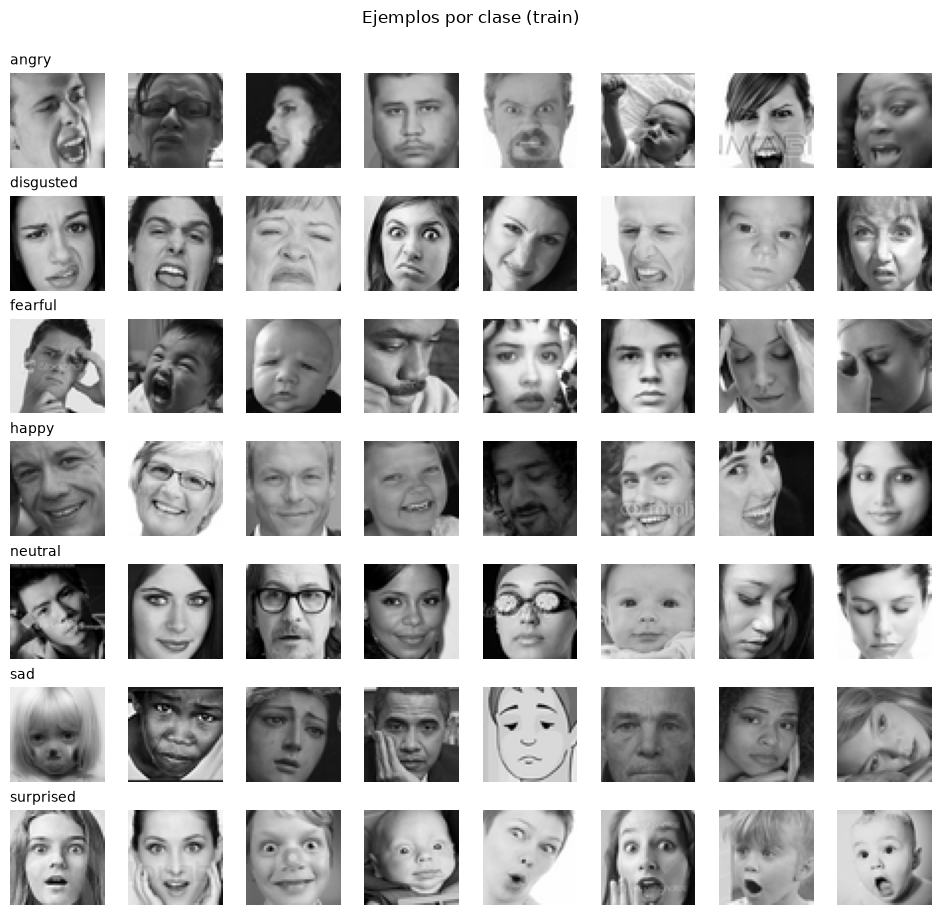

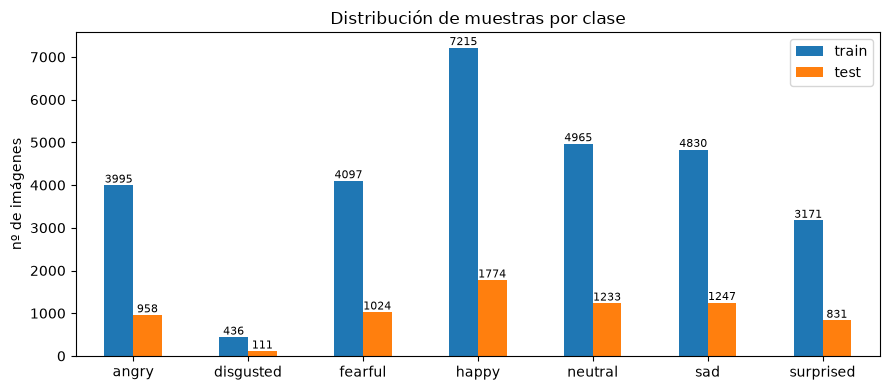

           train  test
angry       3995   958
disgusted    436   111
fearful     4097  1024
happy       7215  1774
neutral     4965  1233
sad         4830  1247
surprised   3171   831

Ratio de desbalanceo en train (máx/mín): 16.5x


In [4]:
# --- Ejemplos de cada clase ---
rng = np.random.default_rng(SEED)
n_show = 8
fig, axes = plt.subplots(N_CLASSES, n_show, figsize=(n_show * 1.2, N_CLASSES * 1.3))
for r, cname in enumerate(CLASS_NAMES):
    idxs = rng.choice(np.where(y_full == r)[0], n_show, replace=False)
    for c, i in enumerate(idxs):
        axes[r, c].imshow(X_full[i], cmap="gray", vmin=0, vmax=255)
        axes[r, c].axis("off")
    axes[r, 0].set_title(cname, loc="left", fontsize=10)
plt.suptitle("Ejemplos por clase (train)", y=1.0)
plt.tight_layout(); plt.show()

# --- Distribución de muestras en train y test ---
counts = pd.DataFrame({
    "train": np.bincount(y_full, minlength=N_CLASSES),
    "test":  np.bincount(y_test, minlength=N_CLASSES),
}, index=CLASS_NAMES)
ax = counts.plot(kind="bar", figsize=(9, 4), rot=0)
for cont in ax.containers: ax.bar_label(cont, fontsize=8)
ax.set_title("Distribución de muestras por clase"); ax.set_ylabel("nº de imágenes")
plt.tight_layout(); plt.show()
print(counts)
print(f"\nRatio de desbalanceo en train (máx/mín): {counts['train'].max() / counts['train'].min():.1f}x")

In [5]:
# --- Validación estratificada 80/20 desde train; test queda reservado SOLO para la evaluación final ---
idx_tr, idx_val = train_test_split(np.arange(len(y_full)), test_size=VAL_SIZE,
                                   stratify=y_full, random_state=SEED)
X_tr,  y_tr  = X_full[idx_tr],  y_full[idx_tr]
X_val, y_val = X_full[idx_val], y_full[idx_val]
print(f"train: {len(y_tr)} | val: {len(y_val)} | test: {len(y_test)}")

# --- class_weight para compensar el desbalanceo (se calcula SOLO con el train) ---
cw = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_tr)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(cw)}
print(pd.Series({CLASS_NAMES[i]: round(w, 2) for i, w in CLASS_WEIGHTS.items()}, name="class_weight").to_frame().T)

train: 22967 | val: 5742 | test: 7178
              angry  disgusted  fearful  happy  neutral   sad  surprised
class_weight   1.03        9.4      1.0   0.57     0.83  0.85       1.29


## 3. Utilidades de evaluación
* `timed_predict`: devuelve predicciones y **ms medios por imagen** (pipeline completo: extracción de características + clasificación). Hace un pequeño calentamiento previo.
* `evaluate`: Accuracy, F1 macro/weighted, informe por clase y registro en `RESULTS`.
* `plot_confusions`: matrices de confusión normalizadas por fila.

In [6]:
RESULTS, PREDS = [], {}      # PREDS[(modelo, conjunto)] = y_pred

def timed_predict(predict_fn, X, warmup=16):
    predict_fn(X[:warmup])                       # calentamiento (carga de pesos, caches...)
    t0 = time.perf_counter()
    y_pred = predict_fn(X)
    ms_per_img = (time.perf_counter() - t0) / len(X) * 1000
    return np.asarray(y_pred), ms_per_img

def evaluate(name, family, y_true, y_pred, ms_img, subset, verbose=True):
    labels = list(range(N_CLASSES))
    row = dict(modelo=name, familia=family, conjunto=subset, n=len(y_true),
               accuracy=accuracy_score(y_true, y_pred),
               f1_macro=f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0),
               f1_weighted=f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0),
               ms_img=ms_img)
    RESULTS.append(row); PREDS[(name, subset)] = np.asarray(y_pred)
    if verbose:
        print(f"[{name} | {subset}] acc={row['accuracy']:.4f}  F1-macro={row['f1_macro']:.4f}  "
              f"F1-weighted={row['f1_weighted']:.4f}  {ms_img:.3f} ms/img")
        print(classification_report(y_true, y_pred, labels=labels, target_names=CLASS_NAMES, zero_division=0))
    return row

def plot_confusions(names, y_true, subset, ncols=3):
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.8 * nrows))
    for ax, name in zip(np.atleast_1d(axes).ravel(), names):
        cm = confusion_matrix(y_true, PREDS[(name, subset)], labels=range(N_CLASSES), normalize="true")
        ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                    xticks_rotation=45, values_format=".2f")
        ax.set_title(f"{name} ({subset})")
    for ax in np.atleast_1d(axes).ravel()[len(names):]: ax.axis("off")
    plt.tight_layout(); plt.show()

## 4. Modelos clásicos
Tres representaciones, todas ajustadas **solo con el split de entrenamiento**:

| Características | Descripción |
|---|---|
| **PCA** | Píxeles /255 → PCA conservando el 95 % de la varianza |
| **HOG** | 9 orientaciones, celdas 6×6, bloques 2×2 |
| **LBP** | LBP uniforme (P=8, R=1) con histogramas en una rejilla 6×6 de celdas |

Cada extractor es una clase con `__call__(X, n_jobs)` (picklable para `joblib`). En entrenamiento se usan todos los núcleos; en **inferencia 1 hilo** para que el tiempo por imagen sea comparable.

In [7]:
def _flat(X): return X.reshape(len(X), -1).astype(np.float32) / 255.0

class PCAFeatures:
    def __init__(self, pca): self.pca = pca
    def __call__(self, X, n_jobs=1): return self.pca.transform(_flat(X))

def _hog1(im):
    return hog(im, orientations=9, pixels_per_cell=(6, 6), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

def _lbp1(im, P=8, R=1, grid=(6, 6)):
    lbp = local_binary_pattern(im, P, R, method="uniform")        # valores 0..P+1
    gh, gw = im.shape[0] // grid[0], im.shape[1] // grid[1]
    feats = []
    for i in range(grid[0]):
        for j in range(grid[1]):
            cell = lbp[i*gh:(i+1)*gh, j*gw:(j+1)*gw].astype(np.int64).ravel()
            feats.append(np.bincount(cell, minlength=P + 2) / cell.size)
    return np.concatenate(feats)

def _extract(fn, X, n_jobs):
    if n_jobs == 1:
        return np.asarray([fn(im) for im in X], dtype=np.float32)
    return np.asarray(Parallel(n_jobs=n_jobs, batch_size=256)(delayed(fn)(im) for im in X), dtype=np.float32)

class HOGFeatures:
    def __call__(self, X, n_jobs=1): return _extract(_hog1, X, n_jobs)

class LBPFeatures:
    def __call__(self, X, n_jobs=1): return _extract(_lbp1, X, n_jobs)

class ClassicModel:
    """extractor -> (scaler opcional) -> clasificador. predict() recibe imágenes (N,48,48) uint8."""
    def __init__(self, name, extractor, scaler, clf):
        self.name, self.extractor, self.scaler, self.clf = name, extractor, scaler, clf
    def features(self, X, n_jobs=1):
        F = self.extractor(X, n_jobs)
        return self.scaler.transform(F) if self.scaler is not None else F
    def predict(self, X): return self.clf.predict(self.features(X, 1))

# --- PCA al 95 % de varianza (ajustado solo con X_tr) ---
t0 = time.time()
pca = PCA(n_components=0.95, svd_solver="full", random_state=SEED).fit(_flat(X_tr))
print(f"PCA: {pca.n_components_} componentes para el 95% de varianza ({time.time()-t0:.1f}s)")

EXTRACTORS = {"PCA": PCAFeatures(pca), "HOG": HOGFeatures(), "LBP": LBPFeatures()}
F_tr, F_val = {}, {}
for k, ext in EXTRACTORS.items():
    t0 = time.time()
    F_tr[k], F_val[k] = ext(X_tr, N_JOBS), ext(X_val, N_JOBS)
    print(f"{k}: {F_tr[k].shape[1]} características  ({time.time()-t0:.1f}s)")

PCA: 252 componentes para el 95% de varianza (5.8s)
PCA: 252 características  (0.2s)
HOG: 1764 características  (3.0s)
LBP: 360 características  (1.6s)


In [8]:
CLASSIC = {}   # nombre -> ClassicModel (ya entrenado)

# ---------------- KNN: k elegido sobre la validación (macro-F1) ----------------
# KNN no admite class_weight; el desbalanceo se refleja en las métricas macro.
for feat in ["PCA", "HOG", "LBP"]:
    best = (-1, None)
    for k in KNN_K_GRID:
        knn = KNeighborsClassifier(n_neighbors=k, n_jobs=N_JOBS).fit(F_tr[feat], y_tr)
        f1 = f1_score(y_val, knn.predict(F_val[feat]), average="macro")
        print(f"KNN-{feat}  k={k:>2}  val F1-macro={f1:.4f}")
        if f1 > best[0]: best = (f1, k)
    knn = KNeighborsClassifier(n_neighbors=best[1], n_jobs=1).fit(F_tr[feat], y_tr)   # n_jobs=1 -> tiempo de inferencia justo
    CLASSIC[f"{feat}+KNN"] = ClassicModel(f"{feat}+KNN", EXTRACTORS[feat], None, knn)
    print(f"  -> {feat}+KNN: k={best[1]}\n")

KNN-PCA  k= 5  val F1-macro=0.3110
KNN-PCA  k=11  val F1-macro=0.2716
KNN-PCA  k=21  val F1-macro=0.2472
  -> PCA+KNN: k=5

KNN-HOG  k= 5  val F1-macro=0.4105
KNN-HOG  k=11  val F1-macro=0.3904
KNN-HOG  k=21  val F1-macro=0.3701
  -> HOG+KNN: k=5

KNN-LBP  k= 5  val F1-macro=0.3048
KNN-LBP  k=11  val F1-macro=0.2907
KNN-LBP  k=21  val F1-macro=0.2646
  -> LBP+KNN: k=5



In [9]:
# ---------------- SVM ----------------
# JUSTIFICACIÓN DE RENDIMIENTO: un SVC con kernel RBF escala entre O(n^2) y O(n^3) con el nº de muestras;
# con ~23k imágenes de train y 1.7k características (HOG) es muy lento. Por eso:
#   * SVM_KIND="rbf"    -> SVC entrenado con un SUBCONJUNTO ESTRATIFICADO de SVM_MAX_TRAIN muestras de train
#   * SVM_KIND="linear" -> LinearSVC con TODO train (escala ~lineal, algo menos expresivo)
# En ambos casos class_weight="balanced" y C elegido sobre la validación (macro-F1).
if SVM_KIND == "rbf" and len(y_tr) > SVM_MAX_TRAIN:
    sub_idx, _ = train_test_split(np.arange(len(y_tr)), train_size=SVM_MAX_TRAIN, stratify=y_tr, random_state=SEED)
else:
    sub_idx = np.arange(len(y_tr))
print(f"SVM ({SVM_KIND}): entrenando con {len(sub_idx)} de {len(y_tr)} muestras de train")
if SVM_KIND == "linear": sub_idx = np.arange(len(y_tr))

def make_svm(C):
    if SVM_KIND == "linear":
        return LinearSVC(C=C, class_weight="balanced", dual="auto", max_iter=5000, random_state=SEED)
    return SVC(kernel="rbf", C=C, gamma="scale", class_weight="balanced", cache_size=1000, random_state=SEED)

for feat in ["PCA", "HOG", "LBP"]:
    scaler = None if feat == "PCA" else StandardScaler().fit(F_tr[feat][sub_idx])   # PCA: gamma="scale" ya se adapta
    tf_ = (lambda F: scaler.transform(F)) if scaler is not None else (lambda F: F)
    Xs, Xv = tf_(F_tr[feat][sub_idx]), tf_(F_val[feat])
    best = (-1, None, None)
    for C in SVM_C_GRID:
        t0 = time.time()
        svm = make_svm(C).fit(Xs, y_tr[sub_idx])
        f1 = f1_score(y_val, svm.predict(Xv), average="macro")
        print(f"SVM-{feat}  C={C:<4} val F1-macro={f1:.4f}  ({time.time()-t0:.0f}s)")
        if f1 > best[0]: best = (f1, C, svm)
    CLASSIC[f"{feat}+SVM"] = ClassicModel(f"{feat}+SVM", EXTRACTORS[feat], scaler, best[2])
    print(f"  -> {feat}+SVM: C={best[1]}\n")

SVM (rbf): entrenando con 10000 de 22967 muestras de train
SVM-PCA  C=1    val F1-macro=0.3574  (14s)
SVM-PCA  C=10   val F1-macro=0.3854  (16s)
  -> PCA+SVM: C=10

SVM-HOG  C=1    val F1-macro=0.4473  (128s)
SVM-HOG  C=10   val F1-macro=0.4608  (146s)
  -> HOG+SVM: C=10

SVM-LBP  C=1    val F1-macro=0.3338  (20s)
SVM-LBP  C=10   val F1-macro=0.3423  (22s)
  -> LBP+SVM: C=10



In [10]:
# ---------------- (Opcional) Stacked: KNN(PCA) + SVM(HOG) + KNN(LBP) -> Regresión logística ----------------
def take_cols(F, start, stop): return F[:, start:stop]

class StackFeatures:
    """Concatena PCA | HOG | LBP y estandariza (los clasificadores base seleccionan su bloque)."""
    def __init__(self, extractors, scaler): self.extractors, self.scaler = extractors, scaler
    def __call__(self, X, n_jobs=1):
        return self.scaler.transform(np.hstack([e(X, n_jobs) for e in self.extractors]))

if RUN_STACKED:
    s_idx, _ = train_test_split(np.arange(len(y_tr)), train_size=min(STACK_MAX_TRAIN, len(y_tr)),
                                stratify=y_tr, random_state=SEED)
    dims = [F_tr[k].shape[1] for k in ("PCA", "HOG", "LBP")]
    edges = np.cumsum([0] + dims)
    F_cat = np.hstack([F_tr[k][s_idx] for k in ("PCA", "HOG", "LBP")])
    st_scaler = StandardScaler().fit(F_cat)

    def block(i): return FunctionTransformer(take_cols, kw_args=dict(start=int(edges[i]), stop=int(edges[i+1])))
    base = [
        ("knn_pca", Pipeline([("sel", block(0)), ("clf", KNeighborsClassifier(n_neighbors=11))])),
        ("svm_hog", Pipeline([("sel", block(1)), ("clf", SVC(kernel="rbf", probability=True,
                                                             class_weight="balanced", random_state=SEED))])),
        ("knn_lbp", Pipeline([("sel", block(2)), ("clf", KNeighborsClassifier(n_neighbors=11))])),
    ]
    stack = StackingClassifier(estimators=base, cv=3, stack_method="predict_proba", n_jobs=1,
                               final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced"))
    t0 = time.time()
    stack.fit(st_scaler.transform(F_cat), y_tr[s_idx])
    print(f"Stacked entrenado con {len(s_idx)} muestras ({time.time()-t0:.0f}s)")
    stack_feat = StackFeatures([EXTRACTORS[k] for k in ("PCA", "HOG", "LBP")], st_scaler)
    CLASSIC["Stacked"] = ClassicModel("Stacked", stack_feat, None, stack)
    print("Val F1-macro Stacked:", round(f1_score(y_val, stack.predict(st_scaler.transform(
        np.hstack([F_val[k] for k in ("PCA", "HOG", "LBP")]))), average="macro"), 4))

/home/cris/miniconda3/envs/VC_P5/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/cris/miniconda3/envs/VC_P5/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/cris/miniconda3/envs/VC_P5/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/cris/miniconda3/envs/VC_P5/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probabilit

Stacked entrenado con 5000 muestras (155s)
Val F1-macro Stacked: 0.3872


In [11]:
# ---------------- Evaluación final en TEST (conjunto completo) + guardado ----------------
PREDICT_FNS = {}     # nombre -> (familia, función imágenes -> etiquetas); se reutiliza en la comparativa con DeepFace
for name, model in CLASSIC.items():
    PREDICT_FNS[name] = ("Clásico", model.predict)
    y_pred, ms = timed_predict(model.predict, X_test)
    evaluate(name, "Clásico", y_test, y_pred, ms, "completo", verbose=False)
    joblib.dump(model, MODELS_DIR / f"{name.replace('+', '_')}.joblib")

pd.DataFrame(RESULTS).round(4)

,modelo,familia,conjunto,n,accuracy,f1_macro,f1_weighted,ms_img
0,PCA+KNN,Clásico,completo,7178,0.3189,0.3032,0.3158,0.0489
1,HOG+KNN,Clásico,completo,7178,0.4565,0.4161,0.4389,0.9570
2,LBP+KNN,Clásico,completo,7178,0.3383,0.3256,0.3348,0.3319
3,PCA+SVM,Clásico,completo,7178,0.4097,0.3902,0.4089,0.9175
4,HOG+SVM,Clásico,completo,7178,0.4994,0.4601,0.4918,7.9712
5,LBP+SVM,Clásico,completo,7178,0.3983,0.3662,0.3913,1.4387
6,Stacked,Clásico,completo,7178,0.4401,0.3938,0.4423,5.1664


## 5. CNN en Keras (entrada 48×48×1)
* 4 bloques `Conv2D → BN → ReLU` (×2) + `MaxPooling2D` + `Dropout`, cabeza `GlobalAveragePooling + Dense`.
* **Data augmentation** dentro del modelo (flip horizontal, rotación ≈ ±11°, zoom ±10 %): solo se activa en entrenamiento, así que el `.keras` guardado se puede usar tal cual con la webcam.
* El reescalado `/255` también va dentro del modelo → **la entrada es la cara en gris 48×48 con valores 0-255**.
* `class_weight` + `EarlyStopping` + `ReduceLROnPlateau` + `ModelCheckpoint`.

In [12]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

def conv_block(x, filters, drop):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(drop)(x)

def build_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 1), n_classes=N_CLASSES):
    inp = keras.Input(shape=input_shape, name="face_gray_48x48")
    x = layers.Rescaling(1.0 / 255)(inp)
    # Data augmentation (solo activa en training)
    x = layers.RandomFlip("horizontal")(x)
    x = layers.RandomRotation(0.03)(x)       # fracción de 2*pi -> ≈ ±10.8°
    x = layers.RandomZoom(0.10)(x)
    for f, d in [(32, 0.25), (64, 0.25), (128, 0.30), (256, 0.30)]:
        x = conv_block(x, f, d)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out, name="cnn_fer")

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Model: "cnn_fer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ face_gray_48x48 (InputLayer)    │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,242,919 (4.74 MB)

 Trainable params: 1,240,487 (4.73 MB)

 Non-trainable params: 2,432 (9.50 KB)

In [13]:
CNN_PATH = MODELS_DIR / "cnn_fer.keras"

def to_cnn_input(X): return X[..., None].astype("float32")      # (N,48,48,1), rango 0-255

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(str(CNN_PATH), monitor="val_loss", save_best_only=True),
]

history = cnn.fit(
    to_cnn_input(X_tr), y_tr,
    validation_data=(to_cnn_input(X_val), y_val),
    epochs=CNN_EPOCHS, batch_size=CNN_BATCH,
    class_weight=CLASS_WEIGHTS,            # compensa el desbalanceo (disgusted pesa mucho más)
    callbacks=callbacks, verbose=2,
)

cnn.save(CNN_PATH)                         # pesos óptimos (restore_best_weights) en formato .keras
json.dump(CLASS_NAMES, open(MODELS_DIR / "class_names.json", "w"))
print("Modelo guardado en", CNN_PATH.resolve())

Epoch 1/80


E0000 00:00:1795618816.484224   20723 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/cnn_fer_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


359/359 - 14s - 38ms/step - accuracy: 0.1787 - loss: 2.1083 - val_accuracy: 0.1818 - val_loss: 1.8806 - learning_rate: 0.0010
Epoch 2/80
359/359 - 7s - 19ms/step - accuracy: 0.2233 - loss: 1.9247 - val_accuracy: 0.1459 - val_loss: 2.0905 - learning_rate: 0.0010
Epoch 3/80
359/359 - 7s - 19ms/step - accuracy: 0.2772 - loss: 1.7938 - val_accuracy: 0.3393 - val_loss: 1.6608 - learning_rate: 0.0010
Epoch 4/80
359/359 - 7s - 19ms/step - accuracy: 0.3581 - loss: 1.6579 - val_accuracy: 0.2992 - val_loss: 1.8251 - learning_rate: 0.0010
Epoch 5/80
359/359 - 7s - 19ms/step - accuracy: 0.4009 - loss: 1.5624 - val_accuracy: 0.4305 - val_loss: 1.4768 - learning_rate: 0.0010
Epoch 6/80
359/359 - 7s - 19ms/step - accuracy: 0.4276 - loss: 1.4856 - val_accuracy: 0.4847 - val_loss: 1.3379 - learning_rate: 0.0010
Epoch 7/80
359/359 - 7s - 19ms/step - accuracy: 0.4488 - loss: 1.4252 - val_accuracy: 0.4505 - val_loss: 1.4092 - learning_rate: 0.0010
Epoch 8/80
359/359 - 7s - 19ms/step - accuracy: 0.4610 - l

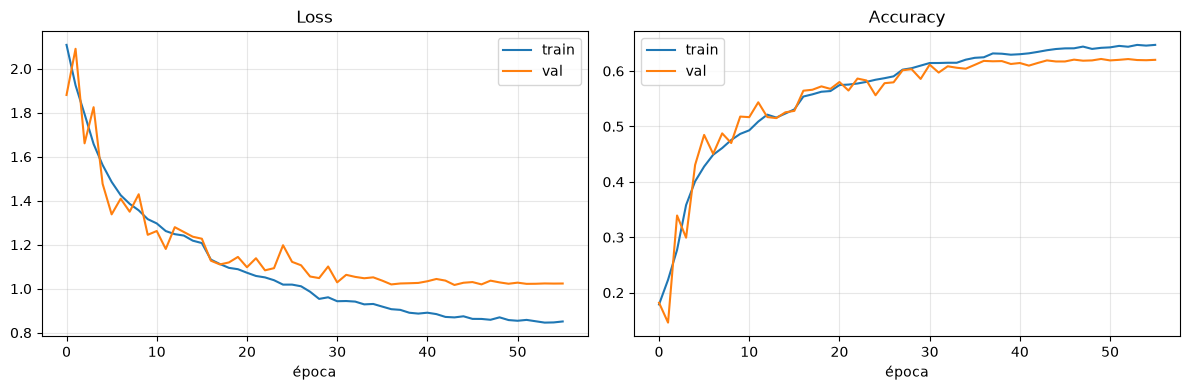

In [14]:
# --- Curvas de entrenamiento ---
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title("Loss")
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val"); ax[1].set_title("Accuracy")
for a in ax: a.set_xlabel("época"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [15]:
# --- Comprobación de que el .keras recarga bien (es lo que usarás en la webcam) y evaluación en TEST ---
cnn_loaded = keras.models.load_model(CNN_PATH)

def cnn_predict(X):
    return np.argmax(cnn_loaded.predict(to_cnn_input(X), batch_size=256, verbose=0), axis=1)

PREDICT_FNS["CNN"] = ("CNN propia", cnn_predict)
y_pred, ms = timed_predict(cnn_predict, X_test)
evaluate("CNN", "CNN propia", y_test, y_pred, ms, "completo")

# Latencia imagen a imagen (caso webcam, batch=1)
sample = to_cnn_input(X_test[:200]); cnn_loaded(sample[:1], training=False)
t0 = time.perf_counter()
for im in sample: cnn_loaded(im[None], training=False)
print(f"CNN latencia con batch=1: {(time.perf_counter()-t0)/len(sample)*1000:.2f} ms/img")

[CNN | completo] acc=0.6230  F1-macro=0.5955  F1-weighted=0.6211  0.153 ms/img
              precision    recall  f1-score   support

       angry       0.53      0.56      0.55       958
   disgusted       0.47      0.61      0.53       111
     fearful       0.48      0.37      0.42      1024
       happy       0.88      0.80      0.83      1774
     neutral       0.52      0.68      0.59      1233
         sad       0.51      0.45      0.48      1247
   surprised       0.73      0.81      0.77       831

    accuracy                           0.62      7178
   macro avg       0.59      0.61      0.60      7178
weighted avg       0.63      0.62      0.62      7178

CNN latencia con batch=1: 14.27 ms/img


## 6. DeepFace
`DeepFace.analyze(actions=['emotion'], enforce_detection=False)` sobre una **muestra estratificada del test** (la misma para todos los modelos en la comparativa directa).

**Mapeo de etiquetas.** El dataset usa `disgusted / fearful / surprised` y DeepFace devuelve `disgust / fear / surprise`.
Se normaliza todo al vocabulario del dataset (índices de `CLASS_NAMES`) para que las matrices de confusión cuadren.

`detector_backend="skip"`: las imágenes ya son caras recortadas de 48×48 y un detector (opencv, retinaface…) suele no encontrarlas a esa resolución; con `skip` DeepFace usa la imagen entera como cara.

In [16]:
from deepface import DeepFace

DEEPFACE_TO_DATASET = {"angry": "angry", "disgust": "disgusted", "fear": "fearful",
                       "happy": "happy", "neutral": "neutral", "sad": "sad", "surprise": "surprised"}
assert set(DEEPFACE_TO_DATASET.values()) == set(CLASS_NAMES), \
    f"Las clases del dataset {CLASS_NAMES} no coinciden con el mapeo de DeepFace"
DF2IDX = {df_lbl: CLASS_NAMES.index(ds_lbl) for df_lbl, ds_lbl in DEEPFACE_TO_DATASET.items()}
print("Mapeo DeepFace -> índice:", DF2IDX)

# --- Muestra estratificada (misma para TODOS los modelos de la comparativa) ---
if DEEPFACE_N and DEEPFACE_N < len(y_test):
    idx_s, _ = train_test_split(np.arange(len(y_test)), train_size=DEEPFACE_N, stratify=y_test, random_state=SEED)
else:
    idx_s = np.arange(len(y_test))
X_s, y_s = X_test[idx_s], y_test[idx_s]
print("Muestra de comparación:", len(y_s), "imágenes | por clase:", dict(zip(CLASS_NAMES, np.bincount(y_s, minlength=N_CLASSES))))

DF_ERRORS = 0
def deepface_predict(X):
    global DF_ERRORS
    preds = []
    for im in tqdm(X, desc="DeepFace", leave=False):
        bgr = cv2.cvtColor(im, cv2.COLOR_GRAY2BGR)           # DeepFace espera BGR de 3 canales
        try:
            res = DeepFace.analyze(img_path=bgr, actions=["emotion"], enforce_detection=False,
                                   detector_backend=DEEPFACE_DETECTOR, silent=True)
            res = res[0] if isinstance(res, list) else res
            preds.append(DF2IDX[res["dominant_emotion"]])
        except Exception as e:
            DF_ERRORS += 1; preds.append(-1)                 # cuenta como acierto fallido
    return np.array(preds)

PREDICT_FNS["DeepFace"] = ("DeepFace", deepface_predict)
y_pred, ms = timed_predict(deepface_predict, X_s)
evaluate("DeepFace", "DeepFace", y_s, y_pred, ms, "muestra")
print("Errores de DeepFace (predicción = -1):", DF_ERRORS)

Mapeo DeepFace -> índice: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
Muestra de comparación: 1000 imágenes | por clase: {'angry': np.int64(133), 'disgusted': np.int64(15), 'fearful': np.int64(143), 'happy': np.int64(247), 'neutral': np.int64(172), 'sad': np.int64(174), 'surprised': np.int64(116)}


DeepFace:   0%|          | 0/16 [00:00<?, ?it/s]

DeepFace:   0%|          | 0/1000 [00:00<?, ?it/s]

[DeepFace | muestra] acc=0.5510  F1-macro=0.5637  F1-weighted=0.5541  7.244 ms/img
              precision    recall  f1-score   support

       angry       0.46      0.44      0.45       133
   disgusted       0.82      0.60      0.69        15
     fearful       0.40      0.38      0.39       143
       happy       0.76      0.72      0.74       247
     neutral       0.48      0.56      0.51       172
         sad       0.37      0.39      0.38       174
   surprised       0.82      0.74      0.78       116

    accuracy                           0.55      1000
   macro avg       0.59      0.55      0.56      1000
weighted avg       0.56      0.55      0.55      1000

Errores de DeepFace (predicción = -1): 0


## 7. Comparativa final

In [17]:
# Todos los modelos propios, evaluados también sobre LA MISMA muestra que DeepFace
for name, (family, fn) in PREDICT_FNS.items():
    if name == "DeepFace": continue
    y_pred, ms = timed_predict(fn, X_s)
    evaluate(name, family, y_s, y_pred, ms, "muestra", verbose=False)

df = pd.DataFrame(RESULTS)
cols = ["modelo", "familia", "n", "accuracy", "f1_macro", "f1_weighted", "ms_img"]

print("=== Comparativa directa sobre la MISMA muestra estratificada de test ===")
df_sample = df[df.conjunto == "muestra"].sort_values("f1_macro", ascending=False)[cols].reset_index(drop=True)
display(df_sample.round(4))

print("=== Modelos propios sobre el TEST completo ===")
df_full = df[df.conjunto == "completo"].sort_values("f1_macro", ascending=False)[cols].reset_index(drop=True)
display(df_full.round(4))

print("=== Mejor modelo de cada familia (muestra, por F1-macro) ===")
display(df_sample.loc[df_sample.groupby("familia")["f1_macro"].idxmax()].round(4).reset_index(drop=True))

df.to_csv(OUT_DIR / "resultados_comparativa.csv", index=False)

=== Comparativa directa sobre la MISMA muestra estratificada de test ===


,modelo,familia,n,accuracy,f1_macro,f1_weighted,ms_img
0,CNN,CNN propia,1000,0.621,0.6034,0.6177,0.8246
1,DeepFace,DeepFace,1000,0.551,0.5637,0.5541,7.2444
2,HOG+SVM,Clásico,1000,0.476,0.4506,0.4693,8.4794
3,HOG+KNN,Clásico,1000,0.445,0.4228,0.4290,0.9544
4,Stacked,Clásico,1000,0.433,0.3884,0.4347,4.8065
5,PCA+SVM,Clásico,1000,0.390,0.3670,0.3883,0.9349
6,LBP+SVM,Clásico,1000,0.364,0.3532,0.3596,1.3991
7,LBP+KNN,Clásico,1000,0.314,0.3162,0.3132,0.3667
8,PCA+KNN,Clásico,1000,0.309,0.2933,0.3029,0.1172


=== Modelos propios sobre el TEST completo ===


,modelo,familia,n,accuracy,f1_macro,f1_weighted,ms_img
0,CNN,CNN propia,7178,0.6230,0.5955,0.6211,0.1532
1,HOG+SVM,Clásico,7178,0.4994,0.4601,0.4918,7.9712
2,HOG+KNN,Clásico,7178,0.4565,0.4161,0.4389,0.9570
3,Stacked,Clásico,7178,0.4401,0.3938,0.4423,5.1664
4,PCA+SVM,Clásico,7178,0.4097,0.3902,0.4089,0.9175
5,LBP+SVM,Clásico,7178,0.3983,0.3662,0.3913,1.4387
6,LBP+KNN,Clásico,7178,0.3383,0.3256,0.3348,0.3319
7,PCA+KNN,Clásico,7178,0.3189,0.3032,0.3158,0.0489


=== Mejor modelo de cada familia (muestra, por F1-macro) ===


,modelo,familia,n,accuracy,f1_macro,f1_weighted,ms_img
0,CNN,CNN propia,1000,0.621,0.6034,0.6177,0.8246
1,HOG+SVM,Clásico,1000,0.476,0.4506,0.4693,8.4794
2,DeepFace,DeepFace,1000,0.551,0.5637,0.5541,7.2444


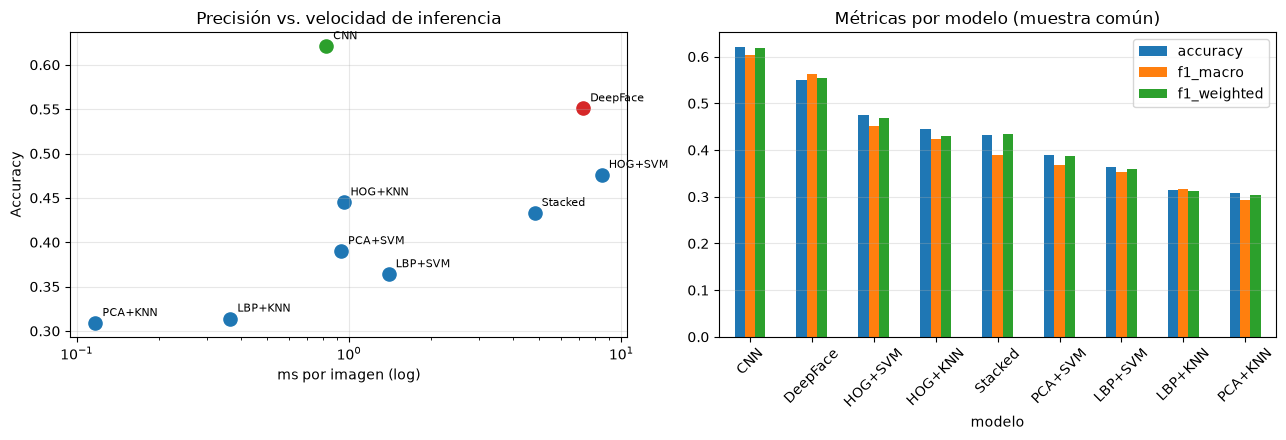

In [18]:
# --- Precisión vs. velocidad (muestra común) ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
colors = {"Clásico": "tab:blue", "CNN propia": "tab:green", "DeepFace": "tab:red"}
for _, r in df_sample.iterrows():
    ax[0].scatter(r.ms_img, r.accuracy, s=90, color=colors[r.familia])
    ax[0].annotate(r.modelo, (r.ms_img, r.accuracy), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax[0].set_xscale("log"); ax[0].set_xlabel("ms por imagen (log)"); ax[0].set_ylabel("Accuracy")
ax[0].set_title("Precisión vs. velocidad de inferencia"); ax[0].grid(alpha=.3)

df_sample.set_index("modelo")[["accuracy", "f1_macro", "f1_weighted"]].plot(kind="bar", ax=ax[1], rot=45)
ax[1].set_title("Métricas por modelo (muestra común)"); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

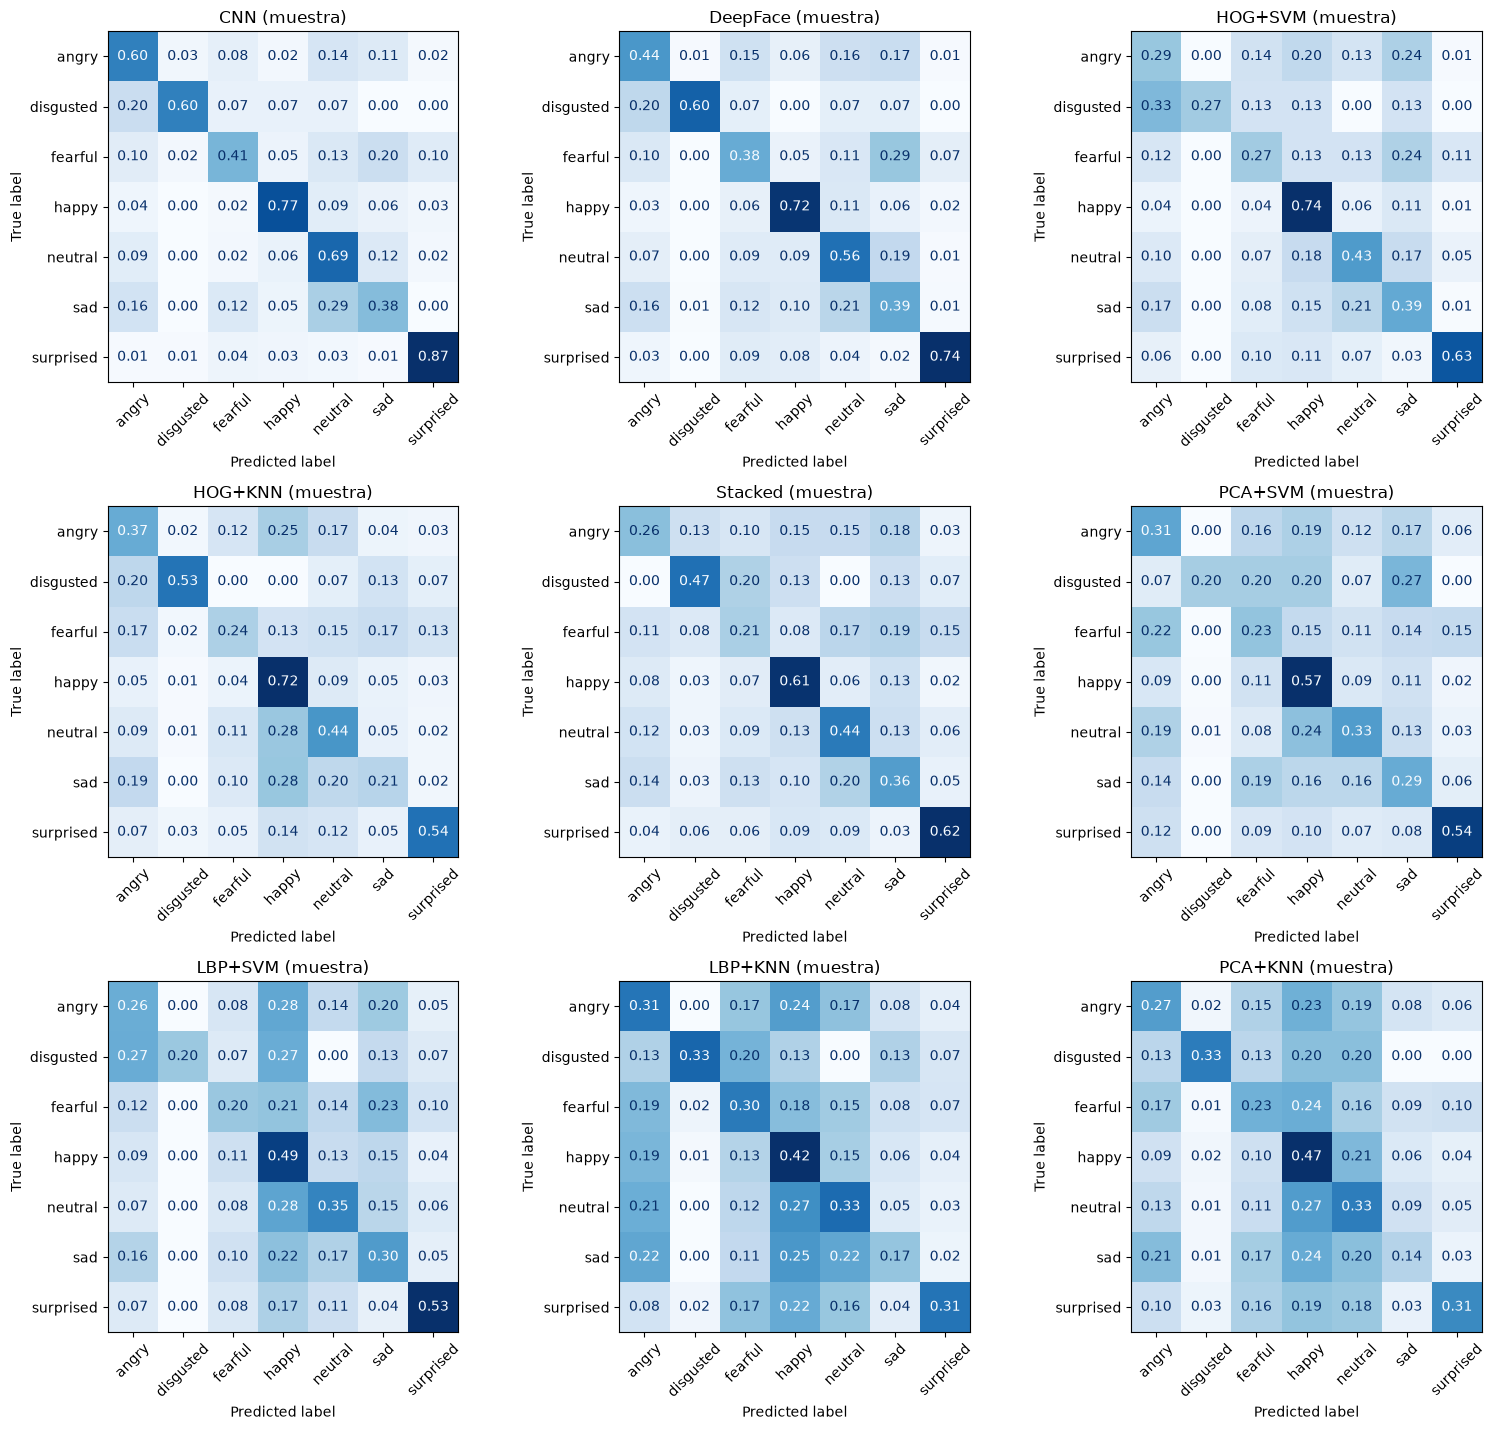

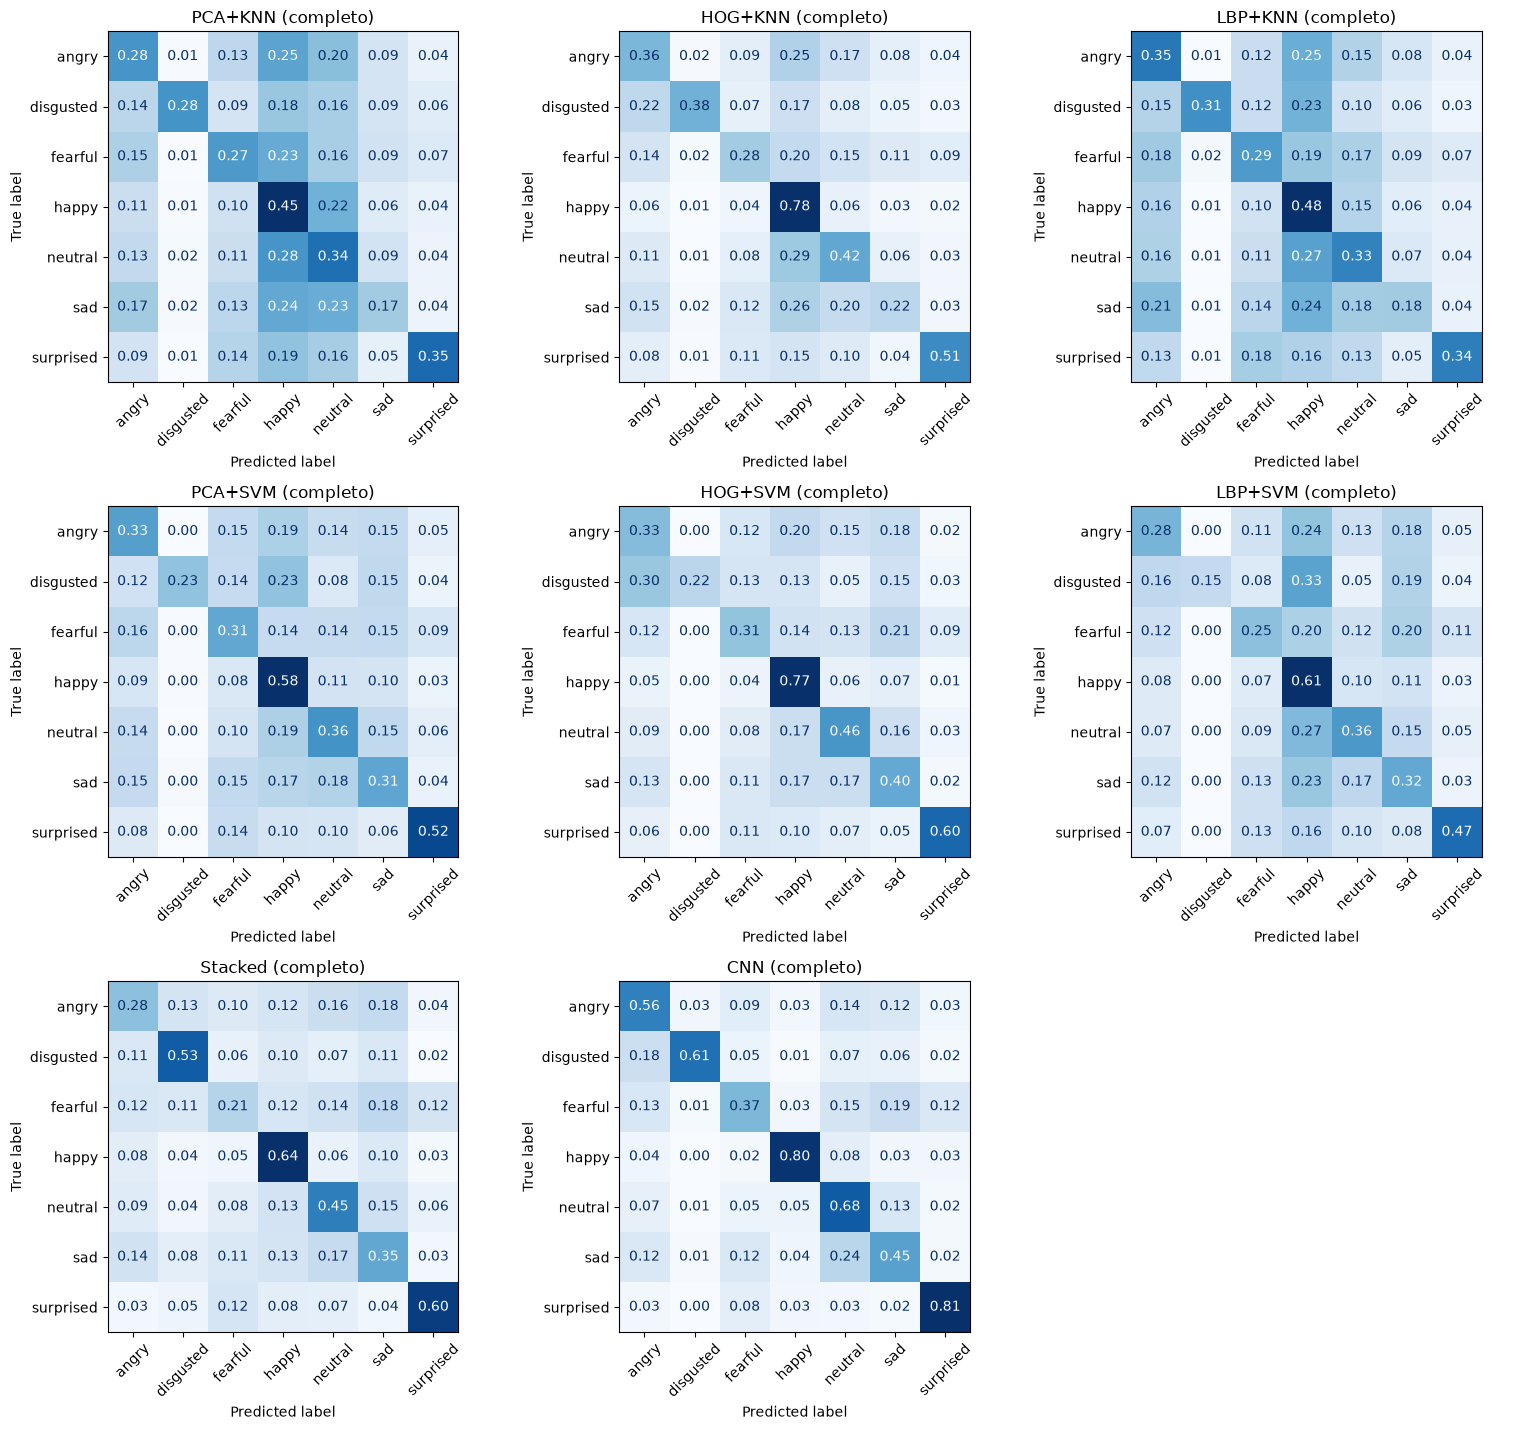

In [19]:
# --- Matrices de confusión ---
plot_confusions(list(df_sample.modelo), y_s, "muestra")                                   # todos, misma muestra
plot_confusions([n for n in PREDICT_FNS if n != "DeepFace"], y_test, "completo")         # propios, test completo

### Notas para la memoria
* **Desbalanceo**: *disgusted* tiene muy pocas muestras; el F1-macro refleja mejor que la accuracy cómo se comporta en las clases minoritarias. La CNN y los SVM usan `class_weight`; KNN no lo admite.
* **SVM**: SVC-RBF entrenado con un subconjunto estratificado (`SVM_MAX_TRAIN`) por coste computacional; alternativa `SVM_KIND="linear"`.
* **Tiempos**: incluyen extracción de características + clasificación, con 1 hilo para los clásicos; la CNN se mide en batch y también con batch=1 (webcam).
* **DeepFace** se evalúa sin detector (`skip`) porque FER ya viene recortado; su modelo de emoción se entrenó con otras condiciones, por lo que es un *baseline* externo.
* **Webcam**: carga `outputs_p5/models/cnn_fer.keras` con `keras.models.load_model`, recorta la cara (p. ej. con MediaPipe), pásala a gris, `cv2.resize(…, (48, 48))` y entra con forma `(1, 48, 48, 1)` y valores 0-255.